7번째 코드
조건2 + 조건3: neutral에 대한 loss가중치 up + neutral vs 4감정 이진분류로직 추가

결과
Train Acc: 94.05% | Val Loss: 0.2968, Val Acc: 88.22%
조기 종료 발동. (Patience: 5)
학습 완료. 모델 저장 경로: /workspace/user1/model_v5_binary/best_neutral_filter.pth

In [1]:
# 환경 설정 및 라이브러리 임포트

import os
import json
import cv2
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import models
import timm
import albumentations as A
from albumentations.pytorch import ToTensorV2
from tqdm import tqdm
import random

# ================= 설정 =================
# 원본 데이터 및 라벨 경로 (dataset_v2)
RAW_IMG_BASE = "/workspace/user1/dataset_v2/img/train" 
LBL_BASE = "/workspace/user1/dataset_v2/label_mod/train"
VAL_IMG_BASE = "/workspace/user1/dataset_v2/img/val"
VAL_LBL_BASE = "/workspace/user1/dataset_v2/label_mod/val"

SAVE_DIR = '/workspace/user1/model_v5_binary'
os.makedirs(SAVE_DIR, exist_ok=True)

SEED = 42
BATCH_SIZE = 64 # 안정적인 메모리 사용을 위해 64 유지
IMG_SIZE = 224
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# 감정 라벨 맵 (원본 기준)
EMOTION_MAP = {'anger': 0, 'happy': 1, 'panic': 2, 'sadness': 3, 'neutral': 4}

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print(f"환경 설정 완료. 장치: {DEVICE}")

환경 설정 완료. 장치: cuda


In [2]:
# 이진 분류용 데이터셋 정의 (Neutral 필터)

class BinaryFilterDataset(Dataset):
    def __init__(self, img_base, lbl_base, transform=None):
        self.transform = transform
        self.samples = []
        
        neutral_count = 0
        emotion_count = 0

        print(f"데이터 로딩 중: {lbl_base}")
        if os.path.exists(lbl_base):
            for json_file in tqdm(os.listdir(lbl_base), desc="Loading JSONs", leave=False):
                if not json_file.endswith('.json'): continue
                with open(os.path.join(lbl_base, json_file), 'r', encoding='utf-8') as f:
                    data = json.load(f)
                    for item in data['images']:
                        if item.get('is_box_issue') == 'Yes': continue
                        
                        original_label = EMOTION_MAP[item['final_emotion']]
                        # [핵심] 이진 분류 라벨링: Neutral은 1, 나머지는 0
                        binary_label = 1 if original_label == 4 else 0
                        
                        if binary_label == 1: neutral_count += 1
                        else: emotion_count += 1

                        self.samples.append({
                            'img_path': os.path.join(img_base, item['final_emotion'], item['filename']),
                            'bbox': item['bbox'],
                            'binary_label': binary_label
                        })

        print(f"로딩 완료. (감정 있음[0]: {emotion_count}장 / Neutral[1]: {neutral_count}장)")

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        item = self.samples[idx]
        image = cv2.imread(item['img_path'])
        
        if image is None: return self.__getitem__(random.randint(0, len(self)-1))
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        
        # 타이트 크롭
        box = item['bbox']
        x1, y1, x2, y2 = max(0, box['minX']), max(0, box['minY']), box['maxX'], box['maxY']
        if x2 <= x1 or y2 <= y1: return self.__getitem__(random.randint(0, len(self)-1))
        
        image = image[y1:y2, x1:x2]
            
        if self.transform:
            image = self.transform(image=image)['image']
            
        return image, torch.tensor(item['binary_label'], dtype=torch.long)

print("BinaryFilterDataset 클래스 정의 완료.")

BinaryFilterDataset 클래스 정의 완료.


In [3]:
# Transform 및 DataLoader 설정

train_transform = A.Compose([
    A.Resize(IMG_SIZE, IMG_SIZE),
    A.HorizontalFlip(p=0.5),
    A.ColorJitter(brightness=0.2, contrast=0.2, p=0.3),
    A.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
    ToTensorV2()
])

val_transform = A.Compose([
    A.Resize(IMG_SIZE, IMG_SIZE),
    A.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
    ToTensorV2()
])

train_dataset = BinaryFilterDataset(RAW_IMG_BASE, LBL_BASE, transform=train_transform)
val_dataset = BinaryFilterDataset(VAL_IMG_BASE, VAL_LBL_BASE, transform=val_transform)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=4, pin_memory=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=4, pin_memory=True)

print("DataLoader 설정 완료.")

데이터 로딩 중: /workspace/user1/dataset_v2/label_mod/train


로딩 완료. (감정 있음[0]: 5329장 / Neutral[1]: 553장)
데이터 로딩 중: /workspace/user1/dataset_v2/label_mod/val


로딩 완료. (감정 있음[0]: 1037장 / Neutral[1]: 126장)
DataLoader 설정 완료.


In [4]:
# 필터 모델(Binary) 로드 및 가중치 손실 함수 설정

def get_binary_model():
    # 이진 분류를 위해 num_classes=2로 설정
    model = timm.create_model('efficientnet_b2', pretrained=True, num_classes=2)
    fer_url = "https://github.com/sb-ai-lab/EmotiEffLib/raw/main/models/affectnet_emotions/enet_b2_8.pt"
    
    print("FER 전용 가중치 주입 중...")
    try:
        loaded = torch.hub.load_state_dict_from_url(fer_url, map_location='cpu', weights_only=False)
        if hasattr(loaded, 'state_dict'): loaded = loaded.state_dict()
        filtered_dict = {k: v for k, v in loaded.items() if 'classifier' not in k and 'head' not in k and 'fc' not in k}
        model.load_state_dict(filtered_dict, strict=False)
        print("가중치 주입 성공.")
    except Exception as e:
        print(f"주입 실패. 기본 가중치 사용. ({e})")
    return model

model = get_binary_model().to(DEVICE)

# [핵심] 클래스 불균형 해결을 위한 Weight 설정
# 0(감정 있음) 데이터가 훨씬 많으므로, 1(Neutral)을 틀렸을 때 패널티를 더 강하게(3.0) 줌
class_weights = torch.tensor([1.0, 3.0]).to(DEVICE)
criterion = nn.CrossEntropyLoss(weight=class_weights)

optimizer = torch.optim.AdamW(model.parameters(), lr=1e-4, weight_decay=1e-2)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.1, patience=2)

print("이진 분류 모델 및 학습 설정 완료.")

FER 전용 가중치 주입 중...
가중치 주입 성공.
이진 분류 모델 및 학습 설정 완료.


In [5]:
# 학습 루프 실행

NUM_EPOCHS = 30
PATIENCE = 5
best_val_loss = float('inf')
trigger_times = 0

SAVE_PATH = os.path.join(SAVE_DIR, 'best_neutral_filter.pth')
scaler = torch.amp.GradScaler('cuda')

print("[이진 분류] 무표정(Neutral) 필터 모델 학습 시작...")

for epoch in range(NUM_EPOCHS):
    model.train()
    running_loss, correct_train, total_train = 0.0, 0, 0

    train_pbar = tqdm(train_loader, desc=f"Ep [{epoch+1}/{NUM_EPOCHS}] Train")
    for images, labels in train_pbar:
        images, labels = images.to(DEVICE), labels.to(DEVICE)
        optimizer.zero_grad()

        with torch.autocast(device_type='cuda', dtype=torch.float16):
            outputs = model(images)
            loss = criterion(outputs, labels)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        running_loss += loss.item() * images.size(0)
        _, predicted = torch.max(outputs, 1)
        total_train += labels.size(0)
        correct_train += (predicted == labels).sum().item()
        train_pbar.set_postfix({'loss': f"{loss.item():.4f}"})

    train_loss = running_loss / len(train_dataset)
    train_acc = correct_train / total_train * 100

    model.eval()
    val_loss, correct_val, total_val = 0.0, 0, 0

    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(DEVICE), labels.to(DEVICE)
            with torch.autocast(device_type='cuda', dtype=torch.float16):
                outputs = model(images)
                loss = criterion(outputs, labels)
            val_loss += loss.item() * images.size(0)
            _, predicted = torch.max(outputs, 1)
            total_val += labels.size(0)
            correct_val += (predicted == labels).sum().item()

    val_loss = val_loss / len(val_dataset)
    val_acc = correct_val / total_val * 100
    
    scheduler.step(val_loss)

    print(f"Train Acc: {train_acc:.2f}% | Val Loss: {val_loss:.4f}, Val Acc: {val_acc:.2f}%")

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        torch.save(model.state_dict(), SAVE_PATH)
        print(f"  -> 저장됨 (Val Loss: {val_loss:.4f})")
        trigger_times = 0
    else:
        trigger_times += 1
        if trigger_times >= PATIENCE:
            print(f"조기 종료 발동. (Patience: {PATIENCE})")
            break

print(f"학습 완료. 모델 저장 경로: {SAVE_PATH}")

[이진 분류] 무표정(Neutral) 필터 모델 학습 시작...


Ep [1/30] Train:   0%|          | 0/92 [00:00<?, ?it/s]Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Ep [1/30] Train:  10%|▉         | 9/92 [00:21<01:26,  1.04s/it, loss=0.2019]Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Ep [1/30] Train:  14%|█▍        | 13/92 [00:26<01:11,  1.10it/s, loss=1.1033]Invalid SOS parameters for sequential JPEG
Invalid SOS parame

Train Acc: 83.68% | Val Loss: 0.2537, Val Acc: 88.74%
  -> 저장됨 (Val Loss: 0.2537)


Ep [2/30] Train:   0%|          | 0/92 [00:00<?, ?it/s]Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Ep [2/30] Train:   3%|▎         | 3/92 [00:04<01:48,  1.22s/it, loss=0.2674]Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Ep [2/30] Train:   8%|▊         | 7/92 [00:08<01:14,  1.14it/s, loss=0.3620]Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Ep [2/30] Train:  13%|█▎        | 12/92 [00:12<00:49,  1.60it/s, loss=0.4278]Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Ep [2/30] Train:  17%|█▋        | 16/92 [00:16<00:45,  1.66it/s, loss=0.2151]Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential

Train Acc: 88.81% | Val Loss: 0.3193, Val Acc: 85.64%


Ep [3/30] Train:   0%|          | 0/92 [00:00<?, ?it/s]Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Ep [3/30] Train:   4%|▍         | 4/92 [00:04<01:06,  1.33it/s, loss=0.1359]Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Ep [3/30] Train:   9%|▊         | 8/92 [00:08<00:51,  1.64it/s, loss=0.1768]Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Ep [3/30] Train:  13%|█▎        | 12/92 [00:12<00:47,  1.70it/

... (3 outputs left out)

Ep [5/30] Train:   0%|          | 0/92 [00:00<?, ?it/s]Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Ep [5/30] Train:   3%|▎         | 3/92 [00:04<01:36,  1.08s/it, loss=0.2083]Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Ep [5/30] Train:   9%|▊         | 8/92 [00:08<00:51,  1.63it/s, loss=0.1745]Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Ep [5/30] Train:  13%|█▎        | 12/92 [00:12<00:43,  1.84it/

Train Acc: 93.76% | Val Loss: 0.2889, Val Acc: 88.05%


Ep [6/30] Train:   0%|          | 0/92 [00:00<?, ?it/s]Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Ep [6/30] Train:   9%|▊         | 8/92 [00:08<00:55,  1.52it/s, loss=0.0708]Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Ep [6/30] Train:  13%|█▎        | 12/92 [00:12<00:48,  1.64it/s, loss=0.1685]Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Ep [6/30] Train:  17%|█▋        | 16/92 [00:15<00:44,  1.71it/s, loss=0.1685]Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for 

Train Acc: 94.05% | Val Loss: 0.2968, Val Acc: 88.22%
조기 종료 발동. (Patience: 5)
학습 완료. 모델 저장 경로: /workspace/user1/model_v5_binary/best_neutral_filter.pth


FER 전용 가중치 주입 중...
가중치 주입 성공.


Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS

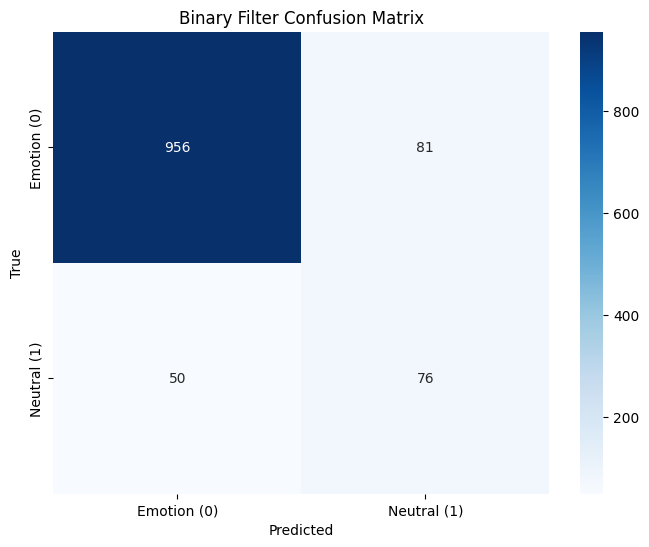

In [6]:
import torch
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# 방금 학습한 이진 분류 모델 로드
model = get_binary_model().to(DEVICE)
model.load_state_dict(torch.load('/workspace/user1/model_v5_binary/best_neutral_filter.pth'))
model.eval()

all_preds, all_labels = [], []
with torch.no_grad():
    for imgs, lbls in val_loader:
        imgs = imgs.to(DEVICE)
        with torch.autocast(device_type='cuda', dtype=torch.float16):
            out = model(imgs)
        all_preds.extend(torch.max(out, 1)[1].cpu().numpy())
        all_labels.extend(lbls.numpy())

# 혼동 행렬 시각화 (0: Emotion, 1: Neutral)
cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['Emotion (0)', 'Neutral (1)'],
            yticklabels=['Emotion (0)', 'Neutral (1)'])
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Binary Filter Confusion Matrix')
plt.show()